### The setup is similar to Battery_Degrad_PINN_0 notebook.

### Now we use capacity-loss data from lithium-ion cells stored at four temperatures: 15°C, 25°C, 35°C, and 45°C instead of just one.

### Source

The experimental data was extracted from:

> Naumann, M. et al., *Analysis and Modeling of Calendar Aging of a Commercial LiFePO₄/Graphite Cell*, Journal of The Electrochemical Society.

📄 **Paper:**  
https://iopscience.iop.org/article/10.1149/2.1181714jes

##**Experimental Setup**

In [33]:
import torch
import torch.nn as nn
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt

# 1. Experimental Data
time_days = [0, 7, 18, 32, 51, 73, 103, 121, 154, 196, 235]
t_data = torch.tensor(time_days, dtype=torch.float32).unsqueeze(1)

# Capacity Loss data at different temperatures
loss_15C = [0.000, 0.030, 0.040, 0.051, 0.062, 0.067, 0.085, 0.088, 0.089, 0.105, 0.112]
loss_25C = [0.000, 0.038, 0.050, 0.063, 0.077, 0.086, 0.103, 0.112, 0.108, 0.130, 0.139]
loss_35C = [0.000, 0.043, 0.063, 0.080, 0.097, 0.113, 0.127, 0.140, 0.153, 0.165, 0.178]
loss_45C = [0.000, 0.054, 0.078, 0.099, 0.128, 0.150, 0.176, 0.188, 0.209, 0.226, 0.244]

# Convert to Capacity Remaining (Q = 1 - Loss)
def to_q_tensor(loss_list):
    return 1.0 - torch.tensor(loss_list, dtype=torch.float32).unsqueeze(1)

q_true = [
    to_q_tensor(loss_15C),
    to_q_tensor(loss_25C),
    to_q_tensor(loss_35C),
    to_q_tensor(loss_45C)
]

##**Plotting the Raw Data**

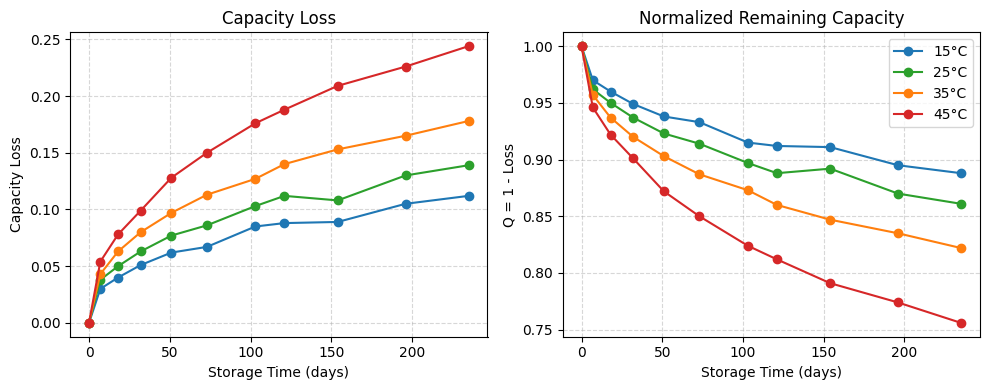

In [34]:

loss_data = [loss_15C, loss_25C, loss_35C, loss_45C]
colors = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
labels = ["15°C", "25°C", "35°C", "45°C"]

fig, ax = plt.subplots(1, 2, figsize=(10,4))

for loss, q, c, lbl in zip(loss_data, q_true, colors, labels):

    # Capacity loss
    ax[0].plot(time_days, loss, "o-", color=c, label=lbl)

    # Remaining capacity
    ax[1].plot(time_days,
               q.numpy().flatten(),
               "o-", color=c, label=lbl)

ax[0].set_title("Capacity Loss")
ax[0].set_xlabel("Storage Time (days)")
ax[0].set_ylabel("Capacity Loss")
ax[0].grid(True, ls="--", alpha=0.5)

ax[1].set_title("Normalized Remaining Capacity")
ax[1].set_xlabel("Storage Time (days)")
ax[1].set_ylabel("Q = 1 - Loss")
ax[1].grid(True, ls="--", alpha=0.5)

ax[1].legend()
plt.tight_layout()
plt.show()

###**Defining the PINN Architechture**



In [35]:
class BatteryPINN(nn.Module):
    def __init__(self):
        super().__init__()

        # 1 input (time) -> 4 outputs (Q at 15°C, 25°C, 35°C, and 45°C)
        self.t_max = 235.0
        self.net = nn.Sequential(
            nn.Linear(1, 32), nn.Tanh(),
            nn.Linear(32, 32), nn.Tanh(),
            nn.Linear(32, 4)
        )

        # PINN: learn SEI and linear-aging rates for each temperature
        self.k_raw = nn.Parameter(torch.full((4,), -5.3))
        self.b_raw = nn.Parameter(torch.full((4,), -9.0))

    @property
    def k(self):
        return F.softplus(self.k_raw)  # Positive SEI rates

    @property
    def b(self):
        return F.softplus(self.b_raw)  # Positive linear-ageing rates

    def forward(self, t):
        return self.net(t / self.t_max)

##<h3>PINN Architechture</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">

The PINN takes storage time as input and predicts  remaining battery capacity for four storage temperatures (15°C, 25°C, 35°C, and 45°C).

Degradation Equation used:
$\Large \sqrt{t} \frac{dQ}{dt}+k+b\sqrt{t}=0$

The model treats **SEI degradation rates (k)** and **linear-ageing rates (b)** as trainable parameters too.
( In the end, an Arrhenius analysis is performed to investigate whether **k** and **b** follow expected degradation behaviour.)

The `softplus` transformation ensures that all learned degradation rates remain physically meaningful (positive).

###**Loss Function Formulation**

In [36]:
def pinn_loss(model, t_data, q_true, t_phys,
              lambda_data=1.0, lambda_phys=10.0, lambda_ic=10.0):

    mse = nn.MSELoss()

    # Data loss
    q_data = model(t_data)
    loss_data = sum(
        mse(q_data[:, i:i+1], q_true[i])
        for i in range(4)
    )

    # Physics loss: sqrt(t)dQ/dt + k + b*sqrt(t) = 0
    q_phys = model(t_phys)
    sqrt_t = torch.sqrt(t_phys)
    loss_phys = 0.0

    for i in range(4):
        dQ_dt = torch.autograd.grad(
            q_phys[:, i:i+1], t_phys,
            grad_outputs=torch.ones_like(q_phys[:, i:i+1]),
            create_graph=True,
            retain_graph=True
        )[0]

        residual = (
            sqrt_t * dQ_dt +
            model.k[i] +
            model.b[i] * sqrt_t
        )

        loss_phys += torch.mean(residual**2)

    # Initial condition: Q(0) = 1
    t0 = torch.zeros((1, 1), device=t_data.device)
    loss_ic = mse(model(t0), torch.ones((1, 4), device=t_data.device))

    # Total loss
    loss_total = (
        lambda_data * loss_data +
        lambda_phys * loss_phys +
        lambda_ic * loss_ic
    )

    return loss_total, loss_data, loss_phys, loss_ic

<h3>PINN Loss Function</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">


$$
\large
L_{\text{Total}}
=
\lambda_{\text{Data}} L_{\text{Data}}
+
\lambda_{\text{Physics}} L_{\text{Physics}}
+
\lambda_{\text{IC}} L_{\text{IC}}
$$

where

$$
L_{\text{Data}}
=
\mathrm{MSE}
\left(
Q_{\text{NN}},
Q_{\text{Data}}
\right)
$$

ensures agreement with the experimental measurements,

$$
L_{\text{Physics}}
=
\mathrm{MSE}
\left(
\sqrt{t}\frac{dQ_{\text{NN}}}{dt}
+
k
+
b\sqrt{t}
\right)
$$

enforces the governing battery-degradation physics, and

$$
L_{\text{IC}}
=
\mathrm{MSE}
\left(
Q_{\text{NN}}(0),
1
\right)
$$

ensures that the battery starts from its known initial condition.

For this study,

$$
\lambda_{\text{Data}} = 1,
\qquad
\lambda_{\text{Physics}} = 10,
\qquad
\lambda_{\text{IC}} = 10
$$



By minimizing the total loss, the PINN learns the degradation trajectory while simultaneously identifying the unknown SEI-growth parameter \(k\) and the linear-ageing parameter \(b\) directly from sparse experimental observations.

---

The PINN is trained using both experimental measurements and physics collocation points(50 points) distributed across the storage-time domain.

Separate learning rates are used for the neural-network weights and the physical parameters (\(k\) and \(b\)), allowing the degradation parameters to converge efficiently.

###**Model Setup and Collocation points**

In [37]:
model = BatteryPINN()

# Physics points exclude t = 0; Q(0) = 1 is enforced through the IC loss
t_phys = torch.linspace(0.1, 235.0, 50).unsqueeze(1).requires_grad_(True)

# Separate learning rates for network and physical parameters
lr_network = 1e-3
lr_physics = 3e-3

optimizer = torch.optim.Adam([
    {"params": model.net.parameters(), "lr": lr_network},
    {"params": [model.k_raw, model.b_raw], "lr": lr_physics}
])

### **Model Training**

In [38]:
epochs = 2000

loss_history = []
data_loss_history = []
physics_loss_history = []
ic_loss_history = []

for epoch in range(epochs + 1):
    model.train()
    optimizer.zero_grad()

    total_loss, data_loss, physics_loss, ic_loss = pinn_loss(
        model, t_data, q_true, t_phys,
        lambda_data=1.0,
        lambda_phys=1.0,
        lambda_ic=1.0
    )

    total_loss.backward()
    optimizer.step()

    loss_history.append(total_loss.item())
    data_loss_history.append(data_loss.item())
    physics_loss_history.append(physics_loss.item())
    ic_loss_history.append(ic_loss.item())

    if epoch % 5000 == 0:
        k_values = model.k.detach().cpu().numpy()
        b_values = model.b.detach().cpu().numpy()

        print(
            f"\nEpoch {epoch:05d} | Total: {total_loss.item():.8f} | "
            f"Data: {data_loss.item():.8f} | Physics: {physics_loss.item():.8f} | "
            f"IC: {ic_loss.item():.8f}"
        )

        for temp, k, b in zip([15, 25, 35, 45], k_values, b_values):
            print(f"{temp}°C | k = {k:.7f} | b = {b:.7f}")


Epoch 00000 | Total: 5.37043095 | Data: 4.14462757 | Physics: 0.00043207 | IC: 1.22537124
15°C | k = 0.0049643 | b = 0.0001230
25°C | k = 0.0049941 | b = 0.0001238
35°C | k = 0.0049643 | b = 0.0001230
45°C | k = 0.0049643 | b = 0.0001230


In [39]:

k_final = model.k.detach().cpu().numpy()
b_final = model.b.detach().cpu().numpy()

print("\n" + "=" * 62 + "\nFINAL DISCOVERED DEGRADATION PARAMETERS\n" + "=" * 62)
print(f"{'Temp':<10} {'k (SEI rate)':<16} {'b (linear)':<16}\n" + "-" * 62)

for i, temp in enumerate([15, 25, 35, 45]):
    print(f"{temp:2d} deg C    {k_final[i]:<16.7f} {b_final[i]:<16.7f}")

print("=" * 62)


FINAL DISCOVERED DEGRADATION PARAMETERS
Temp       k (SEI rate)     b (linear)      
--------------------------------------------------------------
15 deg C    0.0010434        0.0003300       
25 deg C    0.0017676        0.0001818       
35 deg C    0.0036352        0.0001557       
45 deg C    0.0048108        0.0002411       


<h3>PINN Physics Paramerters</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">
    
These are the physical parameters we are interested in.

In [40]:
model.eval()

t_plot = torch.linspace(0, 235, 300).unsqueeze(1)

with torch.no_grad():
    q_pred_plot = model(t_plot)

t_data_np = t_data.cpu().numpy().flatten()
t_plot_np = t_plot.cpu().numpy().flatten()
q_pred_plot_np = q_pred_plot.cpu().numpy()

colors = ["tab:blue", "tab:green", "tab:orange", "tab:red"]
labels = ["15°C", "25°C", "35°C", "45°C"]


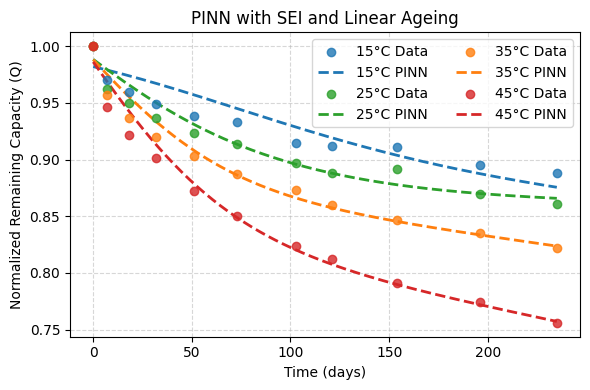

Temperature,R²,RMSE
15°C,0.83289,0.013264
25°C,0.93443,0.010258
35°C,0.96420,0.009934
45°C,0.97667,0.011216


In [41]:
# Plot capacity predictions
plt.figure(figsize=(6, 4))

for i in range(4):
    plt.scatter(
        t_data_np,
        q_true[i].cpu().numpy().flatten(),
        color=colors[i],
        alpha=0.8,
        zorder=3,
        label=f"{labels[i]} Data"
    )

    plt.plot(
        t_plot_np,
        q_pred_plot_np[:, i],
        "--",
        color=colors[i],
        linewidth=2,
        label=f"{labels[i]} PINN"
    )

plt.xlabel("Time (days)")
plt.ylabel("Normalized Remaining Capacity (Q)")
plt.title("PINN with SEI and Linear Ageing")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()


### Let's print R² and RMSE at experimental points

from IPython.display import display, HTML

html = """
<h2>Model Performance</h2>
<table style="font-size:18px; border-collapse:collapse;">
<tr>
    <th style="padding:6px 15px;">Temperature</th>
    <th style="padding:6px 15px;">R²</th>
    <th style="padding:6px 15px;">RMSE</th>
</tr>
"""

for lbl, y_true, y_pred in zip(
    labels,
    [q.cpu().numpy().flatten() for q in q_true],
    [np.interp(t_data_np, t_plot_np, q_pred_plot_np[:, i])
     for i in range(4)]
):

    r2 = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2)
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))

    html += f"""
    <tr>
        <td style="padding:6px 15px;"><b>{lbl}</b></td>
        <td style="padding:6px 15px;">{r2:.5f}</td>
        <td style="padding:6px 15px;">{rmse:.6f}</td>
    </tr>
    """

html += "</table>"

display(HTML(html))


### Plot Training Losses

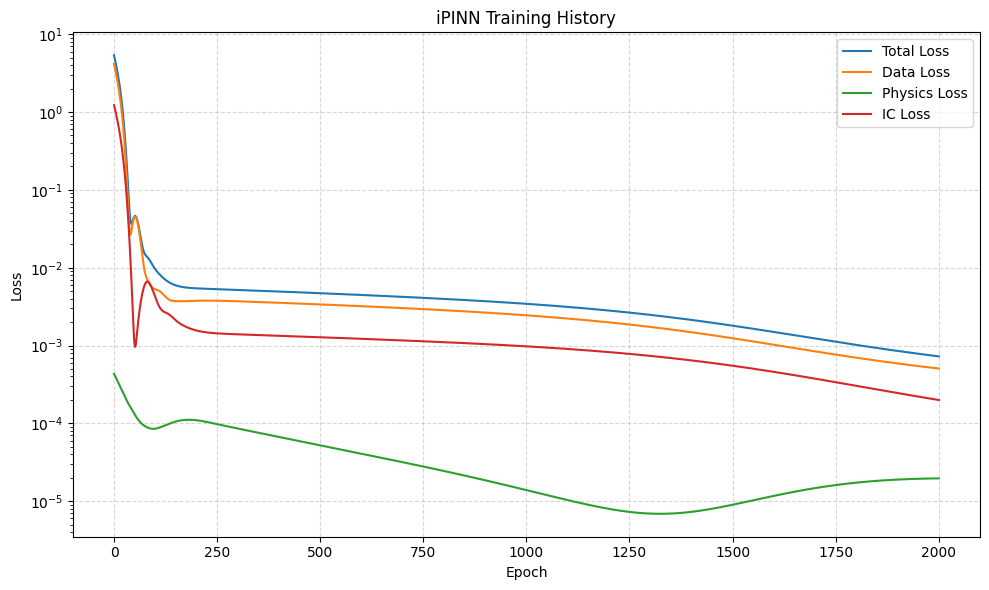

In [42]:
plt.figure(figsize=(10, 6))

plt.semilogy(loss_history, label="Total Loss")
plt.semilogy(data_loss_history, label="Data Loss")
plt.semilogy(physics_loss_history, label="Physics Loss")
plt.semilogy(ic_loss_history, label="IC Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("iPINN Training History")
plt.grid(True, ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Print Final Discovered Parameters

In [43]:
# Redundant duplicate cell of final parameter print was removed during clean-up.

## Arrhenius Law Test

The network independently learns \(k\) and \(b\) at each temperature, and we examine whether the learned parameters follow Arrhenius behaviour. They should !

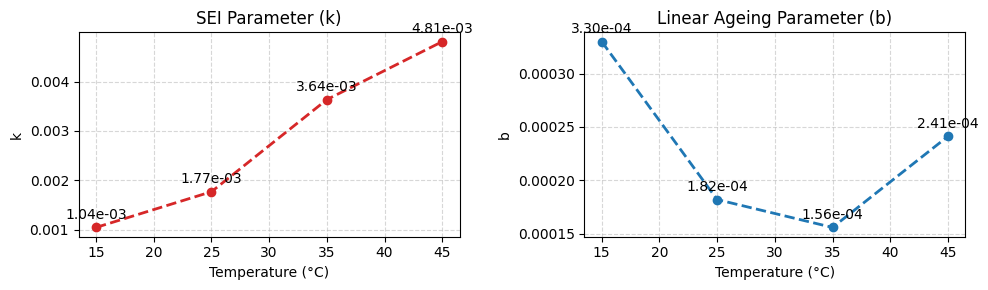

In [44]:

temps = [15, 25, 35, 45]

fig, ax = plt.subplots(1, 2, figsize=(10, 3))

for a, y, title, color in zip(
    ax,
    [k_final, b_final],
    ["SEI Parameter (k)", "Linear Ageing Parameter (b)"],
    ["tab:red", "tab:blue"]
):
    a.plot(temps, y, 'o--', lw=2, color=color)
    a.set_title(title)
    a.set_xlabel("Temperature (°C)")
    a.grid(True, ls='--', alpha=0.5)

    for x, val in zip(temps, y):
        a.annotate(f"{val:.2e}", (x, val), xytext=(0, 6),
                   textcoords="offset points", ha='center')

ax[0].set_ylabel("k")
ax[1].set_ylabel("b")

plt.tight_layout()
plt.show()

<h3>Physics Parameter Inference</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">


A quick inspection of the discovered parameters already suggests that the PINN has identified physically meaningful degradation behaviour.

The SEI-growth parameter **\(k\)** increases monotonically with temperature, indicating accelerated degradation kinetics at elevated temperatures. This trend aligns with the well-established understanding that higher temperatures promote electrochemical side reactions and faster SEI-layer growth.

In contrast, the linear-ageing parameter **\(b\)** remains several orders of magnitude smaller than the SEI contribution, suggesting that the degradation observed under the studied calendar-ageing conditions is dominated primarily by diffusion-limited SEI formation, with only a minor contribution from long-term linear ageing mechanisms.


##**Physics Parameter Inference**

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">


Arrhenius relationship:

$$
k = A \exp\left(-\frac{E_a}{RT}\right)
$$

Taking the natural logarithm gives:

$$
\ln(k) = \ln(A) - \frac{E_a}{R}\left(\frac{1}{T}\right)
$$


Therefore, a linear relationship between **ln(k)** and **1/T** is expected.

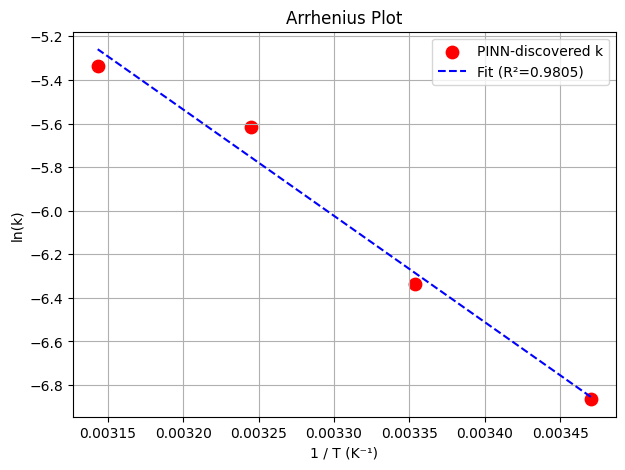

In [45]:
# Temperatures (°C)
T_C = np.array([15, 25, 35, 45])

# Convert to Kelvin
T_K = T_C + 273.15

# Arrhenius variables (using k_final directly since it is already a numpy array)
x = 1 / T_K
y = np.log(k_final)

# Linear regression
slope, intercept = np.polyfit(x, y, 1)

# Predicted line
y_fit = slope * x + intercept

# R²
ss_res = np.sum((y - y_fit)**2)
ss_tot = np.sum((y - np.mean(y))**2)
r2 = 1 - ss_res / ss_tot

# Plot
plt.figure(figsize=(7,5))
plt.scatter(x, y, color='red', s=80, label='PINN-discovered k')
plt.plot(x, y_fit, 'b--', label=f'Fit (R²={r2:.4f})')
plt.xlabel('1 / T (K⁻¹)')
plt.ylabel('ln(k)')
plt.title('Arrhenius Plot')
plt.grid(True)
plt.legend()
plt.show()

R = 8.314  # J/mol-K
Ea = -slope * R

display(HTML(f"""
<div style="font-size:18px; font-weight:bold; color:darkblue;">
    Activation Energy = {Ea/1000:.2f} kJ/mol<br>
    Arrhenius Fit R² = {r2:.4f}
</div>
"""))

<h3>Conclusion</h3>

<div style="font-size: 16px;
border-left: 5px solid #2e86de;
padding: 12px 18px;
background-color: #f8f9fa;
border-radius: 4px;
">

The discovered **SEI-growth parameter** showed a clear temperature dependence and exhibited a strong Arrhenius relationship (**R² ≈ 0.98**).


**Quick Disclaimer:** Infereing unknown parameters using PINN technically constitutes an inverse PINN problem. But  here, I prefer the word PINN for simplicity.